In [6]:
# !nvidia-smi


In [4]:
import numpy as np
import pandas as pd

test_data = pd.read_excel('../data/test_data.xlsx')
train_data = pd.read_excel('../data/train_data.xlsx')



In [5]:
train_data

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302
...,...,...,...,...,...,...,...,...,...,...,...
10678,Air Asia,9/04/2019,Kolkata,Banglore,CCU → BLR,19:55,22:25,2h 30m,non-stop,No info,4107
10679,Air India,27/04/2019,Kolkata,Banglore,CCU → BLR,20:45,23:20,2h 35m,non-stop,No info,4145
10680,Jet Airways,27/04/2019,Banglore,Delhi,BLR → DEL,08:20,11:20,3h,non-stop,No info,7229
10681,Vistara,01/03/2019,Banglore,New Delhi,BLR → DEL,11:30,14:10,2h 40m,non-stop,No info,12648


In [6]:
print(train_data.isnull().sum())
print(test_data.isnull().sum())

Airline            0
Date_of_Journey    0
Source             0
Destination        0
Route              1
Dep_Time           0
Arrival_Time       0
Duration           0
Total_Stops        1
Additional_Info    0
Price              0
dtype: int64
Airline            0
Date_of_Journey    0
Source             0
Destination        0
Route              0
Dep_Time           0
Arrival_Time       0
Duration           0
Total_Stops        0
Additional_Info    0
dtype: int64


In [7]:
train_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10683 entries, 0 to 10682
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Airline          10683 non-null  object
 1   Date_of_Journey  10683 non-null  object
 2   Source           10683 non-null  object
 3   Destination      10683 non-null  object
 4   Route            10682 non-null  object
 5   Dep_Time         10683 non-null  object
 6   Arrival_Time     10683 non-null  object
 7   Duration         10683 non-null  object
 8   Total_Stops      10682 non-null  object
 9   Additional_Info  10683 non-null  object
 10  Price            10683 non-null  int64 
dtypes: int64(1), object(10)
memory usage: 918.2+ KB


In [8]:
train_data['Route'] = train_data['Route'].fillna(train_data['Route'].mode()[0])
train_data['Total_Stops'] =train_data['Total_Stops'].fillna(train_data['Total_Stops'].mode()[0])


In [9]:
print(train_data.isnull().sum())


Airline            0
Date_of_Journey    0
Source             0
Destination        0
Route              0
Dep_Time           0
Arrival_Time       0
Duration           0
Total_Stops        0
Additional_Info    0
Price              0
dtype: int64


In [10]:
# feature engineering and dtypes conversion

# convert datetime and datemonth and extract day and month
train_data['Journey_day'] = pd.to_datetime(train_data.Date_of_Journey, format='%d/%m/%Y').dt.day
train_data['Journey_month'] =  pd.to_datetime(train_data.Date_of_Journey, format='%d/%m/%Y').dt.month

train_data.drop('Date_of_Journey',axis=1,inplace=True)

In [11]:
test_data['Journey_day'] = pd.to_datetime(test_data.Date_of_Journey, format='%d/%m/%Y').dt.day
test_data['Journey_month'] =  pd.to_datetime(test_data.Date_of_Journey, format='%d/%m/%Y').dt.month

test_data.drop('Date_of_Journey',axis=1,inplace=True)

In [12]:
# extracting hours and minutes from dep_time and arrival_time


# departure time for train data
train_data['Dep_hour'] = pd.to_datetime(train_data['Dep_Time']).dt.hour
train_data['Dep_min'] = pd.to_datetime(train_data['Dep_Time']).dt.minute
train_data.drop('Dep_Time',axis=1,inplace=True)


#departure time for test data
test_data['Dep_hour'] = pd.to_datetime(test_data['Dep_Time']).dt.hour
test_data['Dep_min'] = pd.to_datetime(test_data['Dep_Time']).dt.minute
test_data.drop('Dep_Time',axis=1,inplace=True)


# arrival time for train data
train_data['Arrival_hour'] = pd.to_datetime(train_data['Arrival_Time']).dt.hour
train_data['Arrival_min'] = pd.to_datetime(train_data['Arrival_Time']).dt.minute
train_data.drop('Arrival_Time',axis=1,inplace=True)

#arrival time for test_dta
test_data['Arrival_hour'] = pd.to_datetime(test_data['Arrival_Time']).dt.hour
test_data['Arrival_min'] = pd.to_datetime(test_data['Arrival_Time']).dt.minute
test_data.drop('Arrival_Time',axis=1,inplace=True)

C:\Users\Abhishek\AppData\Local\Temp\ipykernel_27264\3215139346.py:5: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  train_data['Dep_hour'] = pd.to_datetime(train_data['Dep_Time']).dt.hour
C:\Users\Abhishek\AppData\Local\Temp\ipykernel_27264\3215139346.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  train_data['Dep_min'] = pd.to_datetime(train_data['Dep_Time']).dt.minute
C:\Users\Abhishek\AppData\Local\Temp\ipykernel_27264\3215139346.py:11: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  test_data['Dep_hour'] = pd.to_datetime(test_data['Dep_Time']).dt.hour
C:\Users\Abhishe

In [13]:
# train_data

In [14]:
train_data['Total_Stops'].value_counts()

Total_Stops
1 stop      5626
non-stop    3491
2 stops     1520
3 stops       45
4 stops        1
Name: count, dtype: int64

In [15]:
train_data.replace({"non-stop": 0, "1 stop": 1, "2 stops": 2, "3 stops": 3, "4 stops": 4}, inplace=True)

C:\Users\Abhishek\AppData\Local\Temp\ipykernel_27264\3326681274.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  train_data.replace({"non-stop": 0, "1 stop": 1, "2 stops": 2, "3 stops": 3, "4 stops": 4}, inplace=True)


In [16]:
test_data.replace({"non-stop": 0, "1 stop": 1, "2 stops": 2, "3 stops": 3, "4 stops": 4}, inplace=True)

C:\Users\Abhishek\AppData\Local\Temp\ipykernel_27264\2556369676.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  test_data.replace({"non-stop": 0, "1 stop": 1, "2 stops": 2, "3 stops": 3, "4 stops": 4}, inplace=True)


In [17]:
# Standardize the duration columns
duration = list(train_data['Duration'])

for i in range(len(duration)):
    if len(duration[i].split()) != 2:
        if 'h' in duration[i]:
            duration[i] = duration[i].strip() + " 0m"
        else:
            duration[i] = "0h " + duration[i]

duration_hours = []
duration_mins = []

for i in range(len(duration)):

    # Extract hours
    duration_hours.append(int(duration[i].split("h")[0]))

    # Extract minutes
    duration_mins.append(int(duration[i].split("m")[0].split()[-1]))

# Assign back to dataframe
train_data["Duration_hours"] = duration_hours
train_data["Duration_mins"] = duration_mins

# Drop original column
train_data.drop('Duration', axis=1, inplace=True)

# Check result
print(train_data[['Duration_hours', 'Duration_mins']].head())

   Duration_hours  Duration_mins
0               2             50
1               7             25
2              19              0
3               5             25
4               4             45


In [18]:
# train_data

In [19]:
# Standardize the duration columns
duration = list(test_data['Duration'])

for i in range(len(duration)):
    if len(duration[i].split()) != 2:
        if 'h' in duration[i]:
            duration[i] = duration[i].strip() + " 0m"
        else:
            duration[i] = "0h " + duration[i]

duration_hours = []
duration_mins = []

for i in range(len(duration)):

    # Extract hours
    duration_hours.append(int(duration[i].split("h")[0]))

    # Extract minutes
    duration_mins.append(int(duration[i].split("m")[0].split()[-1]))

# Assign back to dataframe
test_data["Duration_hours"] = duration_hours
test_data["Duration_mins"] = duration_mins

# Drop original column
test_data.drop('Duration', axis=1, inplace=True)

# Check result
print(test_data[['Duration_hours', 'Duration_mins']].head())

   Duration_hours  Duration_mins
0              10             55
1               4              0
2              23             45
3              13              0
4               2             50


In [20]:
train_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10683 entries, 0 to 10682
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Airline          10683 non-null  object
 1   Source           10683 non-null  object
 2   Destination      10683 non-null  object
 3   Route            10683 non-null  object
 4   Total_Stops      10683 non-null  int64 
 5   Additional_Info  10683 non-null  object
 6   Price            10683 non-null  int64 
 7   Journey_day      10683 non-null  int32 
 8   Journey_month    10683 non-null  int32 
 9   Dep_hour         10683 non-null  int32 
 10  Dep_min          10683 non-null  int32 
 11  Arrival_hour     10683 non-null  int32 
 12  Arrival_min      10683 non-null  int32 
 13  Duration_hours   10683 non-null  int64 
 14  Duration_mins    10683 non-null  int64 
dtypes: int32(6), int64(4), object(5)
memory usage: 1001.7+ KB


In [21]:
# drop route as we already have total stops to prevent multicollinearity

# also additional_info columns has 80% of "No Info" since it lack variance drop it is justified

train_data.drop(['Route','Additional_Info'],axis=1,inplace=True)
test_data.drop(['Route','Additional_Info'],axis=1,inplace=True)


In [22]:
# train_data.info()
test_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2671 entries, 0 to 2670
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Airline         2671 non-null   object
 1   Source          2671 non-null   object
 2   Destination     2671 non-null   object
 3   Total_Stops     2671 non-null   int64 
 4   Journey_day     2671 non-null   int32 
 5   Journey_month   2671 non-null   int32 
 6   Dep_hour        2671 non-null   int32 
 7   Dep_min         2671 non-null   int32 
 8   Arrival_hour    2671 non-null   int32 
 9   Arrival_min     2671 non-null   int32 
 10  Duration_hours  2671 non-null   int64 
 11  Duration_mins   2671 non-null   int64 
dtypes: int32(6), int64(3), object(3)
memory usage: 187.9+ KB


In [23]:
# One hot endcoding the Airline ,Source and Destination Columns

Airline = pd.get_dummies(train_data['Airline'],prefix='Airline',drop_first=True,dtype=int)
Source = pd.get_dummies(train_data['Source'],prefix='Source',drop_first=True,dtype=int)
Destination= pd.get_dummies(train_data['Destination'],prefix='Dest',drop_first=True,dtype=int)

In [24]:
train_data = pd.concat([train_data,Airline,Source,Destination],axis=1)


In [25]:
train_data.drop(['Airline', 'Source', 'Destination'],axis=1,inplace=True)

In [26]:
train_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10683 entries, 0 to 10682
Data columns (total 30 columns):
 #   Column                                     Non-Null Count  Dtype
---  ------                                     --------------  -----
 0   Total_Stops                                10683 non-null  int64
 1   Price                                      10683 non-null  int64
 2   Journey_day                                10683 non-null  int32
 3   Journey_month                              10683 non-null  int32
 4   Dep_hour                                   10683 non-null  int32
 5   Dep_min                                    10683 non-null  int32
 6   Arrival_hour                               10683 non-null  int32
 7   Arrival_min                                10683 non-null  int32
 8   Duration_hours                             10683 non-null  int64
 9   Duration_mins                              10683 non-null  int64
 10  Airline_Air India                          106

In [27]:
test_data.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2671 entries, 0 to 2670
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Airline         2671 non-null   object
 1   Source          2671 non-null   object
 2   Destination     2671 non-null   object
 3   Total_Stops     2671 non-null   int64 
 4   Journey_day     2671 non-null   int32 
 5   Journey_month   2671 non-null   int32 
 6   Dep_hour        2671 non-null   int32 
 7   Dep_min         2671 non-null   int32 
 8   Arrival_hour    2671 non-null   int32 
 9   Arrival_min     2671 non-null   int32 
 10  Duration_hours  2671 non-null   int64 
 11  Duration_mins   2671 non-null   int64 
dtypes: int32(6), int64(3), object(3)
memory usage: 187.9+ KB


In [28]:
print(test_data.columns)

Index(['Airline', 'Source', 'Destination', 'Total_Stops', 'Journey_day',
       'Journey_month', 'Dep_hour', 'Dep_min', 'Arrival_hour', 'Arrival_min',
       'Duration_hours', 'Duration_mins'],
      dtype='object')


In [29]:
Airline_test = pd.get_dummies(test_data['Airline'],prefix='Airline', drop_first=True, dtype=int)
Source_test = pd.get_dummies(test_data['Source'],prefix='Source', drop_first=True, dtype=int)
Destination_test = pd.get_dummies(test_data['Destination'],prefix='Dest', drop_first=True, dtype=int)

test_data = pd.concat([test_data, Airline_test, Source_test, Destination_test], axis=1)

# 3. Drop the original text columns from test data
test_data.drop(['Airline', 'Source', 'Destination'], axis=1, inplace=True)

In [30]:
test_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2671 entries, 0 to 2670
Data columns (total 28 columns):
 #   Column                                     Non-Null Count  Dtype
---  ------                                     --------------  -----
 0   Total_Stops                                2671 non-null   int64
 1   Journey_day                                2671 non-null   int32
 2   Journey_month                              2671 non-null   int32
 3   Dep_hour                                   2671 non-null   int32
 4   Dep_min                                    2671 non-null   int32
 5   Arrival_hour                               2671 non-null   int32
 6   Arrival_min                                2671 non-null   int32
 7   Duration_hours                             2671 non-null   int64
 8   Duration_mins                              2671 non-null   int64
 9   Airline_Air India                          2671 non-null   int64
 10  Airline_GoAir                              2671 

In [31]:
# train data has one more columns due to more airlines
missing_cols = set(train_data.columns) - set(test_data.columns) - {'Price'}

for col in missing_cols :
  test_data[col] = 0



In [32]:
train_data.shape,test_data.shape

((10683, 30), (2671, 29))

In [33]:
test_data = test_data[train_data.columns.drop('Price')]

In [34]:
train_data.shape,test_data.shape

((10683, 30), (2671, 29))

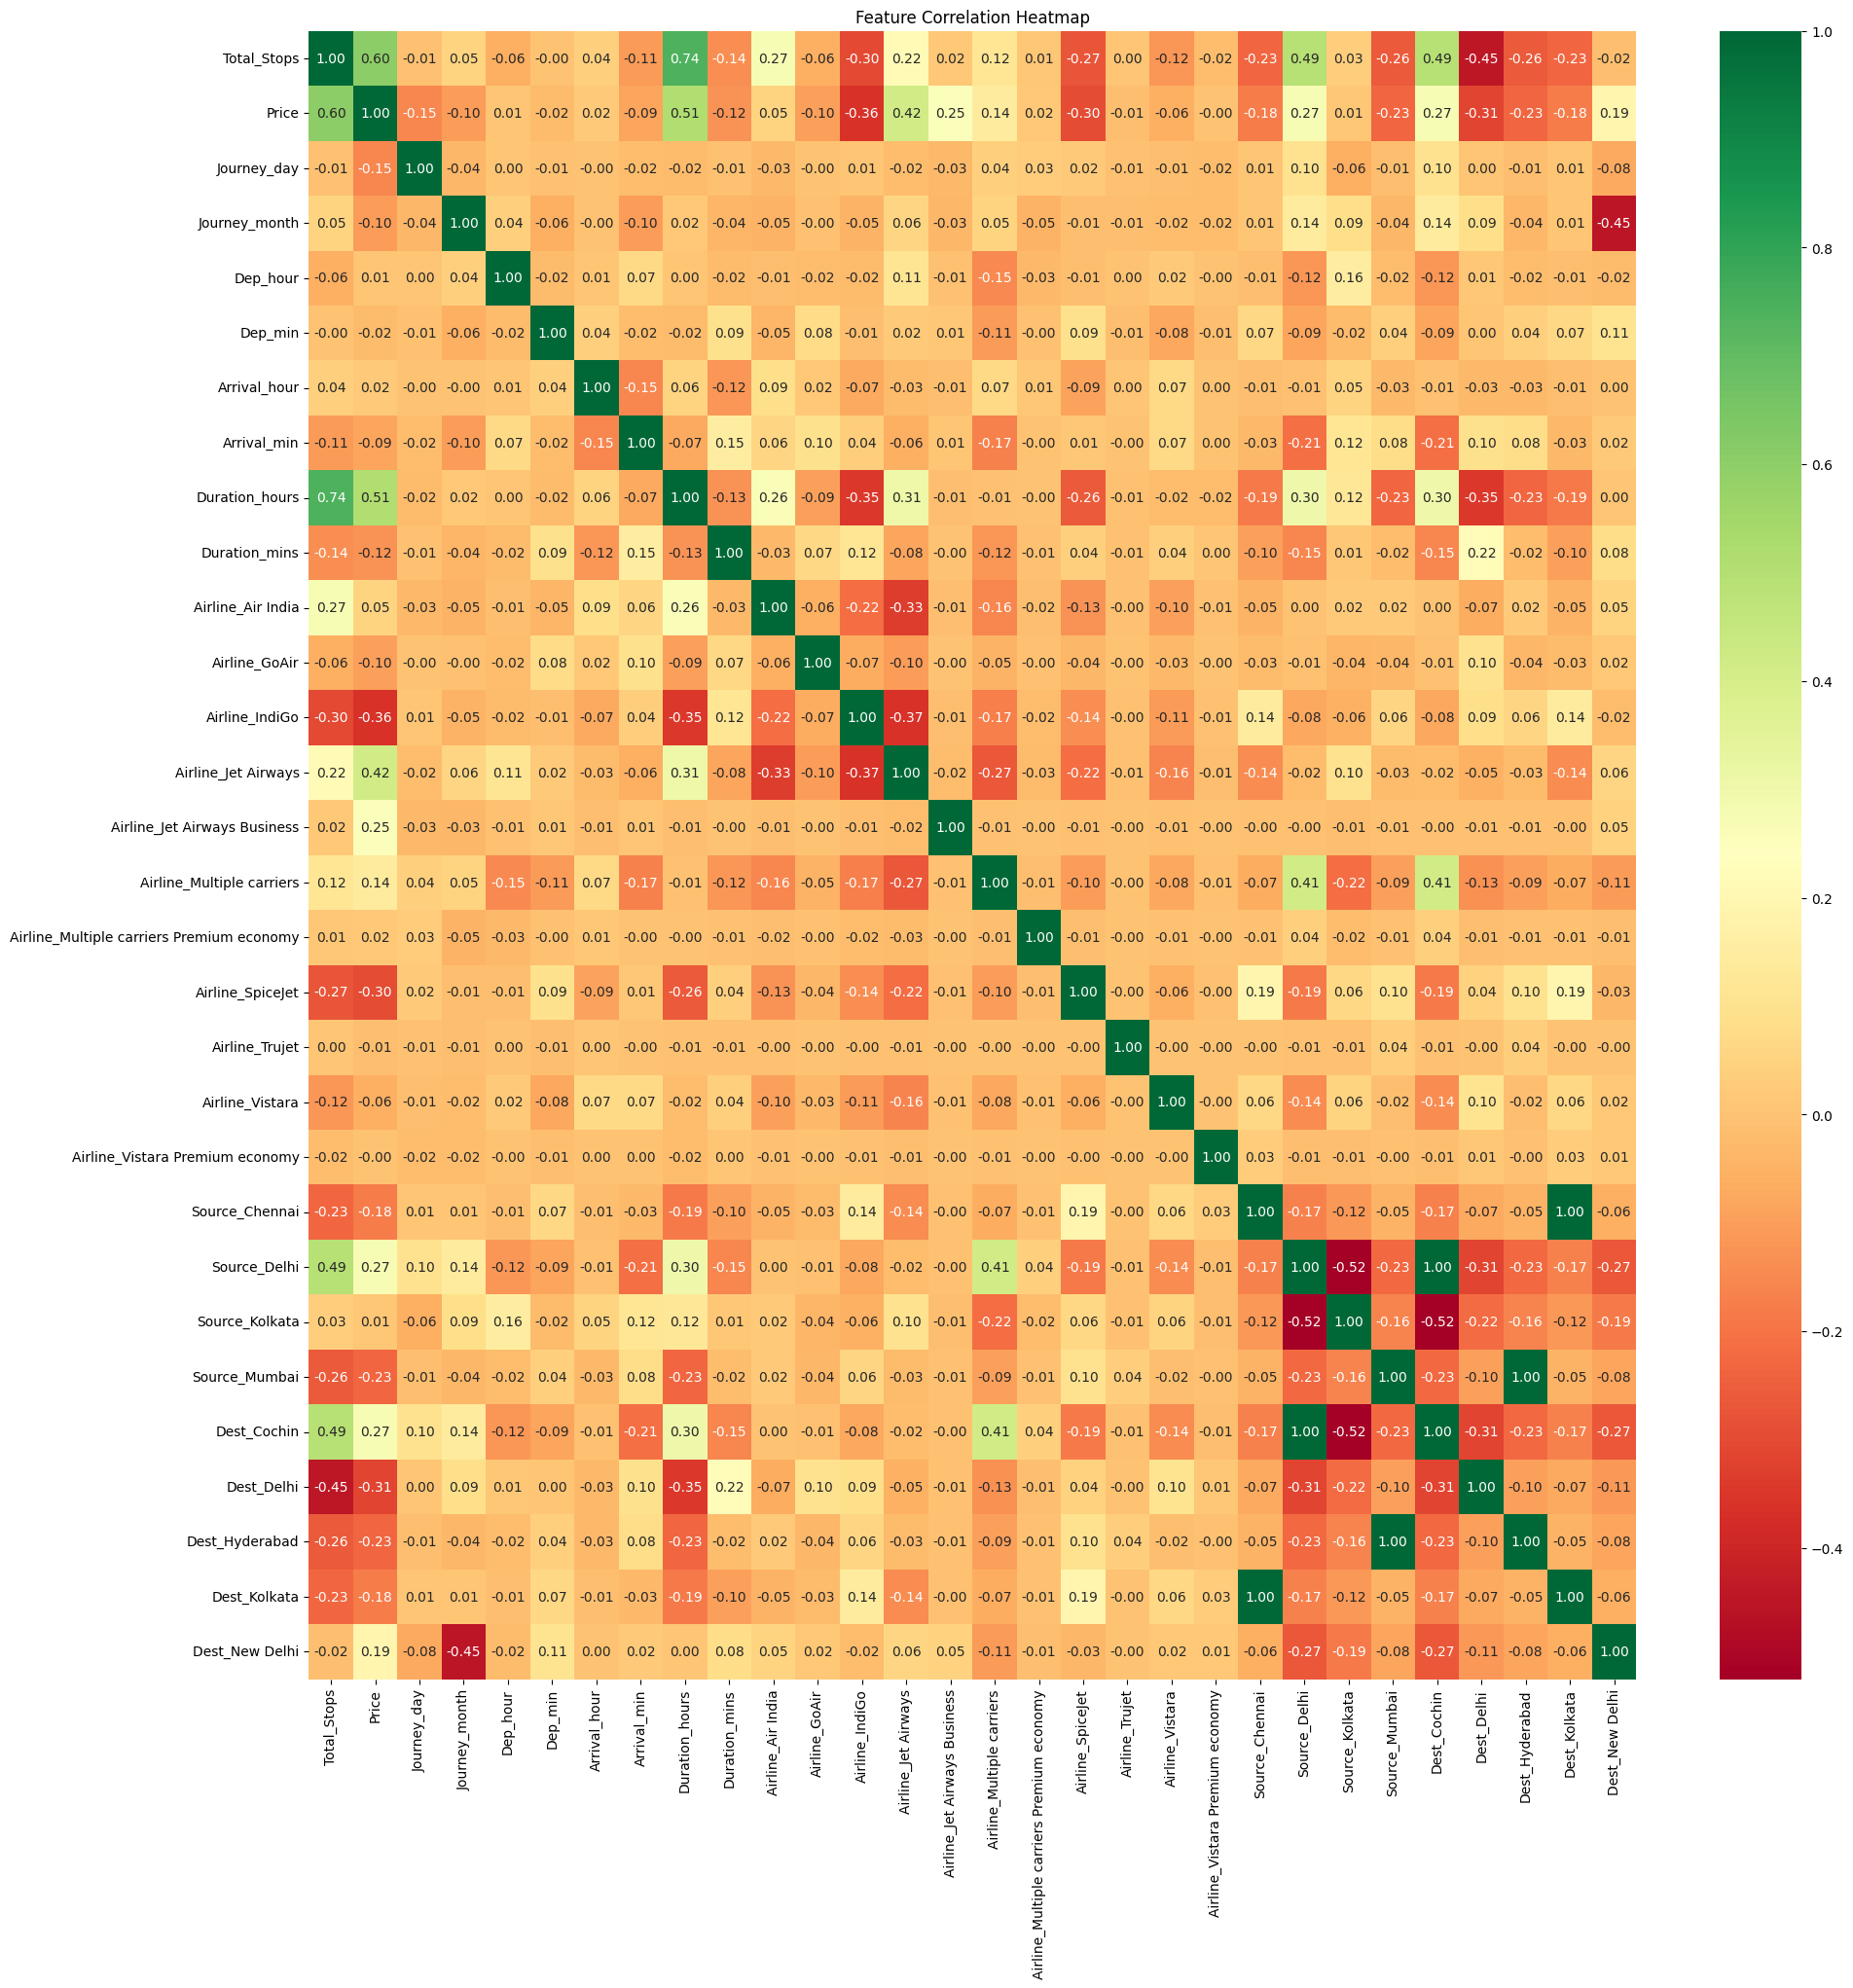

In [35]:
# feature correlation
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(22,22))
sns.heatmap(train_data.corr(),annot=True,cmap='RdYlGn',fmt='.2f')
plt.title("Feature Correlation Heatmap")
plt.show()

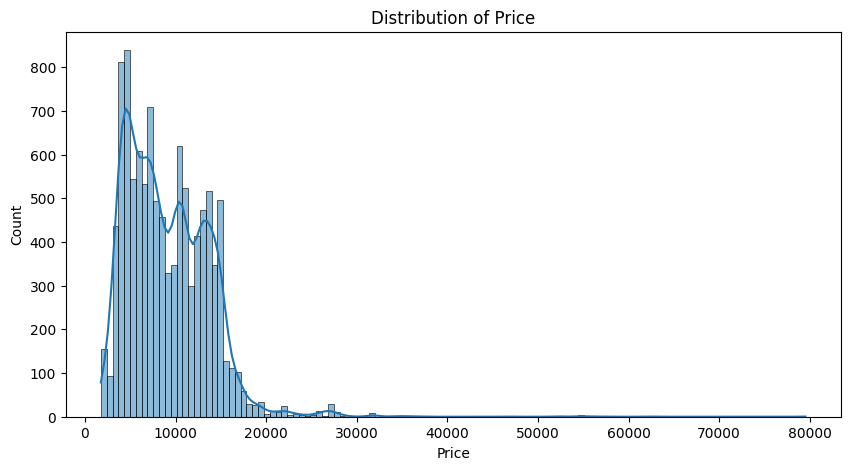

In [39]:
plt.figure(figsize=(10,5))

sns.histplot(train_data['Price'],kde=True,)
plt.title("Distribution of Price")
plt.show()

In [36]:
from sklearn.model_selection import train_test_split

X = train_data.drop('Price',axis=1)
y = train_data['Price']

X_train,X_val,y_train,y_val = train_test_split(X,y,test_size=0.2,random_state=42)

In [37]:
X_train.columns.tolist()

['Total_Stops',
 'Journey_day',
 'Journey_month',
 'Dep_hour',
 'Dep_min',
 'Arrival_hour',
 'Arrival_min',
 'Duration_hours',
 'Duration_mins',
 'Airline_Air India',
 'Airline_GoAir',
 'Airline_IndiGo',
 'Airline_Jet Airways',
 'Airline_Jet Airways Business',
 'Airline_Multiple carriers',
 'Airline_Multiple carriers Premium economy',
 'Airline_SpiceJet',
 'Airline_Trujet',
 'Airline_Vistara',
 'Airline_Vistara Premium economy',
 'Source_Chennai',
 'Source_Delhi',
 'Source_Kolkata',
 'Source_Mumbai',
 'Dest_Cochin',
 'Dest_Delhi',
 'Dest_Hyderabad',
 'Dest_Kolkata',
 'Dest_New Delhi']

In [41]:
X_train.shape,y_train.shape

((8546, 29), (8546,))

In [42]:
# model training
from sklearn.tree import  DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error,r2_score,mean_absolute_error
from sklearn.model_selection import GridSearchCV

In [43]:
def evaluate_model(name,y_val,y_pred) :
  print(f"----------{name}-------------")
  print(f"R2Score : {r2_score(y_val,y_pred):.4f}")
  print(f"MAE : {mean_absolute_error(y_val,y_pred):.4f}\n")
  print(f"MSE : {mean_squared_error(y_val,y_pred):.4f}\n")


In [44]:
dt_model = DecisionTreeRegressor()
rf_model = RandomForestRegressor()
xgb_model = XGBRegressor()

print("Training Model : ")
dt_model.fit(X_train,y_train)
rf_model.fit(X_train,y_train)
xgb_model.fit(X_train,y_train)


y_pred_dt = dt_model.predict(X_val)
y_pred_rf =  rf_model.predict(X_val)
y_pred_xgb = xgb_model.predict(X_val)

Training Model : 


In [45]:
evaluate_model("Decision Tree",y_val,y_pred_dt)
evaluate_model("Random Forest",y_val,y_pred_rf)
evaluate_model("XG Boost",y_val,y_pred_xgb)

----------Decision Tree-------------
R2Score : 0.6904
MAE : 1376.6847

MSE : 6553245.0719

----------Random Forest-------------
R2Score : 0.7840
MAE : 1206.6883

MSE : 4570417.1502

----------XG Boost-------------
R2Score : 0.8518
MAE : 1125.7897

MSE : 3137055.7500



In [46]:
xgb_model = XGBRegressor(tree_method='hist', device='cuda', random_state=42)


In [47]:
# Hyperparamter Tunning the best performing XBG and Random Forest

from sklearn.model_selection import RandomizedSearchCV

xgb_param_grid = {
    "n_estimators"      : [100, 200, 300, 500],
    "max_depth"         : [7, 9,13],
    "learning_rate"     : [0.1, 0.2,0.3],
    "subsample"         : [0.6, 0.8, 1.0],
    "colsample_bytree"  : [0.6, 0.8, 1.0],
    "min_child_weight"  : [1, 3, 5],
}

rf_param_grid = {
    "n_estimators"      : [100, 200, 300, 500],
    "max_depth"         : [None, 10, 20, 30],
    "min_samples_split" : [2, 5, 10],
    "min_samples_leaf"  : [1, 2, 4],
    "max_features"      : ["sqrt", "log2", 0.3, 0.5],
    "bootstrap"         : [True, False],
    "criterion"         : ["squared_error", "friedman_mse"],
}
# Tell XGBoost to use the GPU!

rf_random =RandomizedSearchCV(estimator=rf_model,param_distributions=rf_param_grid,
                              n_iter=30,cv=5,verbose=2,random_state=42,n_jobs=-1)
xgb_random =RandomizedSearchCV(estimator=xgb_model,param_distributions=xgb_param_grid,
                              n_iter=80,cv=5,verbose=2,random_state=42,n_jobs=-1)

xgb_random.fit(X_train,y_train)
rf_random.fit(X_train,y_train)

# extracting the best models
best_rf = rf_random.best_estimator_
best_xgb = xgb_random.best_estimator_

print("\n---------Best Parameter------------")
print(f"Random Forest : {rf_random.best_params_}")
print(f"XGBoost : {xgb_random.best_params_}\n")


best_rf_pred = best_rf.predict(X_val)
best_xgb_pred = best_xgb.predict(X_val)

evaluate_model("Random Forest",y_val,best_rf_pred)
evaluate_model("XGBoost ",y_val,best_xgb_pred)

Fitting 5 folds for each of 80 candidates, totalling 400 fits


/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [16:48:00] WARNING: /__w/xgboost/xgboost/src/context.cc:53: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [16:48:00] WARNING: /__w/xgboost/xgboost/src/context.cc:207: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  bst.update(dtrain, iteration=i, fobj=obj)


Fitting 5 folds for each of 30 candidates, totalling 150 fits

---------Best Parameter------------
Random Forest : {'n_estimators': 300, 'min_samples_split': 10, 'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': 20, 'criterion': 'squared_error', 'bootstrap': True}
XGBoost : {'subsample': 1.0, 'n_estimators': 300, 'min_child_weight': 3, 'max_depth': 7, 'learning_rate': 0.1, 'colsample_bytree': 0.8}

----------Random Forest-------------
R2Score : 0.8352
MAE : 1165.0161

MSE : 3487355.6839

----------XGBoost -------------
R2Score : 0.8422
MAE : 1119.4512

MSE : 3338936.7500



In [48]:
# xgb_param_grid = {
#     "n_estimators"      : [100, 200, 300, 500],
#     "max_depth"         : [3, 5, 7, 9],
#     "learning_rate"     : [0.3, 0.1, 0.2],
#     "subsample"         : [ 0.8, 1.0],
#     "colsample_bytree"  : [0.8, 1.0]
# }
# xgb_random =GridSearchCV(estimator=xgb_model,param_grid=xgb_param_grid,
#                               cv=3,verbose=2,n_jobs=-1)


# xgb_random.fit(X_train,y_train)
# best_xgb = xgb_random.best_estimator_

# print(f"XGBoost : {xgb_random.best_params_}\n")
# best_xgb_pred = best_xgb.predict(X_val)


# evaluate_model("XGBoost ",y_val,best_xgb_pred)

In [50]:
import pickle

final_preds = best_xgb.predict(test_data)

submission = pd.DataFrame({'Predicted Price' : final_preds})

submission.to_csv('flight_price_predictions.csv',index=False)

submission.to_csv('flight_price_predictions.csv', index=False)
print("✅ Predictions successfully saved to 'flight_price_predictions.csv'")

with open('best_xgboost_flight_model.pkl', 'wb') as file:
    pickle.dump(best_xgb, file)
print("✅ Model successfully saved as 'best_xgboost_flight_model.pkl'")

✅ Predictions successfully saved to 'flight_price_predictions.csv'
✅ Model successfully saved as 'best_xgboost_flight_model.pkl'
